# Step 4a — Multi-Model Churn Comparison

Compares 7 scikit-learn classifiers on an expanded, engineered feature set
(see `scripts/feature_eng.py`), each tuned via `RandomizedSearchCV`, and
picks a winner by test-set ROC-AUC. The winning fitted pipeline is saved to
`models/best_churn_model.joblib` -- `churn_clv_model.ipynb` loads it from
there rather than retraining or assuming a specific model.

**Input:** `data/cleaned_telco.csv`
**Output:** `models/best_churn_model.joblib`, comparison table + charts inline below

In [1]:
import os
import sys


def find_project_root(marker="requirements.txt"):
    path = os.getcwd()
    for _ in range(5):
        if os.path.exists(os.path.join(path, marker)):
            return path
        path = os.path.dirname(path)
    raise FileNotFoundError(f"Could not locate project root (looked for {marker})")


PROJECT_ROOT = find_project_root()
sys.path.insert(0, os.path.join(PROJECT_ROOT, "scripts"))
print(f"PROJECT_ROOT = {PROJECT_ROOT}")

PROJECT_ROOT = C:\Users\DEVKUMAR\OneDrive\Desktop\DA_Project


In [2]:
from plot_style import CATEGORICAL, INK_SECONDARY, apply_style
from feature_eng import engineer_features, NUMERIC_FEATURES, CATEGORICAL_FEATURES, FEATURES

import time

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    RocCurveDisplay, average_precision_score, classification_report,
    f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight

CLEANED_PATH = os.path.join(PROJECT_ROOT, "data", "cleaned_telco.csv")
MODELS_DIR = os.path.join(PROJECT_ROOT, "models")
MODEL_PATH = os.path.join(MODELS_DIR, "best_churn_model.joblib")
os.makedirs(MODELS_DIR, exist_ok=True)

apply_style()
RANDOM_STATE = 42

## Load data, engineer features, split

In [3]:
df = pd.read_csv(CLEANED_PATH)
df = engineer_features(df)

X = df[FEATURES]
y = df["ChurnFlag"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

sw_train = compute_sample_weight("balanced", y_train)

print(f"Train: {len(X_train)}, Test: {len(X_test)}, churn rate in test: {y_test.mean():.3f}")
print(f"Features: {len(NUMERIC_FEATURES)} numeric + {len(CATEGORICAL_FEATURES)} categorical = {len(FEATURES)} total")

Train: 5282, Test: 1761, churn rate in test: 0.265
Features: 6 numeric + 18 categorical = 24 total


## Preprocessor + tuning helper

One shared `ColumnTransformer` builder (scaling toggled per model, since only distance/gradient-based models like Logistic Regression, SVM, and k-NN need it) and one `tune_and_evaluate` helper every model below calls -- keeps the per-model cells short and the evaluation logic (and its imbalance handling) consistent.

In [4]:
def build_preprocessor(scale_numeric):
    numeric_step = StandardScaler() if scale_numeric else "passthrough"
    return ColumnTransformer([
        ("num", numeric_step, NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ])


results = []
fitted_pipes = {}


def tune_and_evaluate(name, clf, param_dist, scale_numeric, n_iter, cv, use_sample_weight=False):
    """RandomizedSearchCV on the training set only (leak-free), then a single
    evaluation pass on the held-out test set. `use_sample_weight` is for
    models without a class_weight param (Gradient Boosting, Naive Bayes)."""
    pipe = Pipeline([
        ("prep", build_preprocessor(scale_numeric)),
        ("clf", clf),
    ])

    fit_params = {}
    if use_sample_weight:
        fit_params["clf__sample_weight"] = sw_train

    search = RandomizedSearchCV(
        pipe, param_dist, n_iter=n_iter, cv=StratifiedKFold(cv, shuffle=True, random_state=RANDOM_STATE),
        scoring="roc_auc", random_state=RANDOM_STATE, n_jobs=-1)

    start = time.time()
    search.fit(X_train, y_train, **fit_params)
    elapsed = time.time() - start

    best_pipe = search.best_estimator_
    proba = best_pipe.predict_proba(X_test)[:, 1]
    preds = (proba >= 0.5).astype(int)

    row = {
        "Model": name,
        "CV ROC-AUC": search.best_score_,
        "Test ROC-AUC": roc_auc_score(y_test, proba),
        "Test PR-AUC": average_precision_score(y_test, proba),
        "Precision (Churn)": precision_score(y_test, preds),
        "Recall (Churn)": recall_score(y_test, preds),
        "F1 (Churn)": f1_score(y_test, preds),
        "Tune time (s)": elapsed,
        "Best params": search.best_params_,
    }
    results.append(row)
    fitted_pipes[name] = best_pipe

    print(f"--- {name} ({elapsed:.0f}s) ---")
    test_auc = row["Test ROC-AUC"]
    cv_auc = row["CV ROC-AUC"]
    print(f"Test ROC-AUC: {test_auc:.4f}  |  CV ROC-AUC: {cv_auc:.4f}")
    print(f"Best params: {search.best_params_}")
    print(classification_report(y_test, preds, target_names=["Retained", "Churned"]))

    return best_pipe

## Logistic Regression

Interpretable linear baseline, kept for continuity with the earlier version of this notebook.

In [5]:
tune_and_evaluate(
    "Logistic Regression",
    LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE),
    param_dist={"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100]},
    scale_numeric=True, n_iter=8, cv=5)

--- Logistic Regression (4s) ---
Test ROC-AUC: 0.8489  |  CV ROC-AUC: 0.8464
Best params: {'clf__C': 0.03}
              precision    recall  f1-score   support

    Retained       0.91      0.74      0.81      1294
     Churned       0.52      0.79      0.63       467

    accuracy                           0.75      1761
   macro avg       0.71      0.77      0.72      1761
weighted avg       0.81      0.75      0.77      1761



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['tenure','MonthlyCharges','TotalCharges',...,'PaymentMethod', 'Contract_Internet','TenureBucket']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pas

## Decision Tree

Interpretable non-linear baseline -- a single tree, distinct from the Random Forest ensemble below.

In [6]:
tune_and_evaluate(
    "Decision Tree",
    DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    param_dist={
        "clf__max_depth": [3, 5, 7, 10, 15, None],
        "clf__min_samples_leaf": [5, 10, 20, 50],
        "clf__criterion": ["gini", "entropy"],
    },
    scale_numeric=False, n_iter=15, cv=5)

--- Decision Tree (1s) ---
Test ROC-AUC: 0.8331  |  CV ROC-AUC: 0.8259
Best params: {'clf__min_samples_leaf': 50, 'clf__max_depth': 10, 'clf__criterion': 'entropy'}
              precision    recall  f1-score   support

    Retained       0.91      0.74      0.82      1294
     Churned       0.52      0.79      0.63       467

    accuracy                           0.75      1761
   macro avg       0.72      0.77      0.72      1761
weighted avg       0.81      0.75      0.77      1761



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['tenure','MonthlyCharges','TotalCharges',...,'PaymentMethod', 'Contract_Internet','TenureBucket']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pas

## Random Forest

The model this project used exclusively before -- now tuned and compared on equal footing with the rest, on the expanded feature set.

In [7]:
tune_and_evaluate(
    "Random Forest",
    RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    param_dist={
        "clf__n_estimators": [100, 200, 300, 400],
        "clf__max_depth": [4, 6, 8, 10, None],
        "clf__min_samples_leaf": [5, 10, 20],
    },
    scale_numeric=False, n_iter=15, cv=5)

--- Random Forest (11s) ---
Test ROC-AUC: 0.8473  |  CV ROC-AUC: 0.8469
Best params: {'clf__n_estimators': 200, 'clf__min_samples_leaf': 20, 'clf__max_depth': None}
              precision    recall  f1-score   support

    Retained       0.91      0.75      0.82      1294
     Churned       0.53      0.80      0.64       467

    accuracy                           0.76      1761
   macro avg       0.72      0.78      0.73      1761
weighted avg       0.81      0.76      0.77      1761



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['tenure','MonthlyCharges','TotalCharges',...,'PaymentMethod', 'Contract_Internet','TenureBucket']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pas

## Gradient Boosting

`GradientBoostingClassifier` has no `class_weight` parameter, so imbalance is handled via `sample_weight` instead (computed once above with `compute_sample_weight`).

In [8]:
tune_and_evaluate(
    "Gradient Boosting",
    GradientBoostingClassifier(random_state=RANDOM_STATE),
    param_dist={
        "clf__n_estimators": [100, 200, 300],
        "clf__learning_rate": [0.01, 0.05, 0.1, 0.2],
        "clf__max_depth": [2, 3, 4],
        "clf__min_samples_leaf": [10, 20, 50],
    },
    scale_numeric=False, n_iter=12, cv=5, use_sample_weight=True)

--- Gradient Boosting (22s) ---
Test ROC-AUC: 0.8453  |  CV ROC-AUC: 0.8456
Best params: {'clf__n_estimators': 100, 'clf__min_samples_leaf': 20, 'clf__max_depth': 2, 'clf__learning_rate': 0.05}
              precision    recall  f1-score   support

    Retained       0.91      0.73      0.81      1294
     Churned       0.52      0.81      0.63       467

    accuracy                           0.75      1761
   macro avg       0.72      0.77      0.72      1761
weighted avg       0.81      0.75      0.76      1761



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['tenure','MonthlyCharges','TotalCharges',...,'PaymentMethod', 'Contract_Internet','TenureBucket']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pas

## Support Vector Machine

RBF kernel, `probability=True` for the predicted probabilities the rest of the project relies on. This is the slowest model to tune here -- `SVC`'s probability calibration runs an internal CV on every fit -- so it gets a smaller search budget (3-fold instead of 5) to keep runtime reasonable.

In [9]:
tune_and_evaluate(
    "SVM (RBF)",
    SVC(class_weight="balanced", probability=True, random_state=RANDOM_STATE),
    param_dist={
        "clf__C": [0.1, 1, 10, 100],
        "clf__gamma": ["scale", "auto", 0.01, 0.1],
    },
    scale_numeric=True, n_iter=8, cv=3)

C:\Users\DEVKUMAR\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


--- SVM (RBF) (37s) ---
Test ROC-AUC: 0.8401  |  CV ROC-AUC: 0.8375
Best params: {'clf__gamma': 'auto', 'clf__C': 0.1}
              precision    recall  f1-score   support

    Retained       0.85      0.87      0.86      1294
     Churned       0.61      0.58      0.60       467

    accuracy                           0.79      1761
   macro avg       0.73      0.73      0.73      1761
weighted avg       0.79      0.79      0.79      1761



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['tenure','MonthlyCharges','TotalCharges',...,'PaymentMethod', 'Contract_Internet','TenureBucket']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pas

## k-Nearest Neighbors

**Limitation worth noting:** k-NN has no rebalancing mechanism at all (no `class_weight`, no meaningful `sample_weight` for a non-parametric distance-based model) -- with 26.5% churn, its neighborhoods are dominated by the majority class by default. Included anyway for a complete comparison; expect this to be the weakest model here specifically *because* of that gap, not because k-NN is inherently bad.

In [10]:
tune_and_evaluate(
    "k-Nearest Neighbors",
    KNeighborsClassifier(),
    param_dist={
        "clf__n_neighbors": [5, 10, 15, 20, 30, 50],
        "clf__weights": ["uniform", "distance"],
    },
    scale_numeric=True, n_iter=10, cv=5)

--- k-Nearest Neighbors (3s) ---
Test ROC-AUC: 0.8412  |  CV ROC-AUC: 0.8379
Best params: {'clf__weights': 'uniform', 'clf__n_neighbors': 50}
              precision    recall  f1-score   support

    Retained       0.86      0.86      0.86      1294
     Churned       0.60      0.61      0.61       467

    accuracy                           0.79      1761
   macro avg       0.73      0.73      0.73      1761
weighted avg       0.79      0.79      0.79      1761



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['tenure','MonthlyCharges','TotalCharges',...,'PaymentMethod', 'Contract_Internet','TenureBucket']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pas

## Gaussian Naive Bayes

Cheap baseline. Its independence assumption is a poor fit for one-hot encoded, correlated categorical features (e.g. `Contract` and `Contract_Internet` are directly derived from each other) -- included for completeness, not because it's expected to compete.

In [11]:
tune_and_evaluate(
    "Naive Bayes",
    GaussianNB(),
    param_dist={"clf__var_smoothing": [1e-11, 1e-10, 1e-9, 1e-8, 1e-7]},
    scale_numeric=False, n_iter=5, cv=5, use_sample_weight=True)

--- Naive Bayes (1s) ---
Test ROC-AUC: 0.8231  |  CV ROC-AUC: 0.8272
Best params: {'clf__var_smoothing': 1e-11}
              precision    recall  f1-score   support

    Retained       0.92      0.63      0.75      1294
     Churned       0.45      0.85      0.59       467

    accuracy                           0.69      1761
   macro avg       0.69      0.74      0.67      1761
weighted avg       0.80      0.69      0.71      1761



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['tenure','MonthlyCharges','TotalCharges',...,'PaymentMethod', 'Contract_Internet','TenureBucket']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pas

## Comparison table

In [12]:
comparison = pd.DataFrame(results).drop(columns="Best params").sort_values("Test ROC-AUC", ascending=False).reset_index(drop=True)
comparison_display = comparison.copy()
for col in ["CV ROC-AUC", "Test ROC-AUC", "Test PR-AUC", "Precision (Churn)", "Recall (Churn)", "F1 (Churn)"]:
    comparison_display[col] = comparison_display[col].round(4)
comparison_display["Tune time (s)"] = comparison_display["Tune time (s)"].round(1)
comparison_display

,Model,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Precision (Churn),Recall (Churn),F1 (Churn),Tune time (s)
0,Logistic Regression,0.8464,0.8489,0.6554,0.5219,0.7923,0.6293,4.2
1,Random Forest,0.8469,0.8473,0.6485,0.5350,0.8030,0.6421,11.4
2,Gradient Boosting,0.8456,0.8453,0.6482,0.5208,0.8051,0.6325,21.7
3,k-Nearest Neighbors,0.8379,0.8412,0.6212,0.6043,0.6081,0.6062,2.9
4,SVM (RBF),0.8375,0.8401,0.6433,0.6121,0.5846,0.5980,37.0
5,Decision Tree,0.8259,0.8331,0.6270,0.5240,0.7944,0.6315,0.9
6,Naive Bayes,0.8272,0.8231,0.5907,0.4528,0.8522,0.5914,0.7


## Chart: test ROC-AUC by model

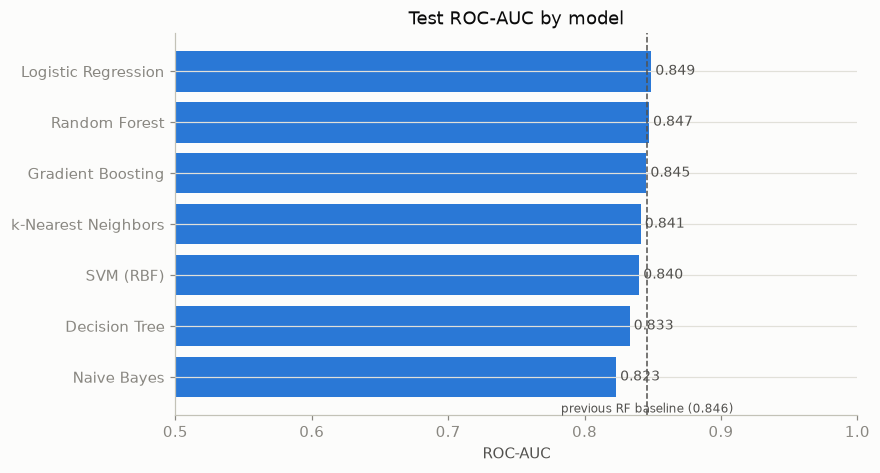

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))
d = comparison.sort_values("Test ROC-AUC", ascending=True)
ax.barh(d["Model"], d["Test ROC-AUC"], color=CATEGORICAL[0])
for i, v in enumerate(d["Test ROC-AUC"]):
    ax.text(v, i, f" {v:.3f}", va="center", fontsize=9, color=INK_SECONDARY)
ax.set_xlim(0.5, 1.0)
ax.axvline(0.846, color=INK_SECONDARY, linewidth=1, linestyle="--")
ax.annotate("previous RF baseline (0.846)", (0.846, -0.7), fontsize=8, color=INK_SECONDARY, ha="center")
ax.set_title("Test ROC-AUC by model")
ax.set_xlabel("ROC-AUC")
plt.show()

## Chart: ROC curves, all models

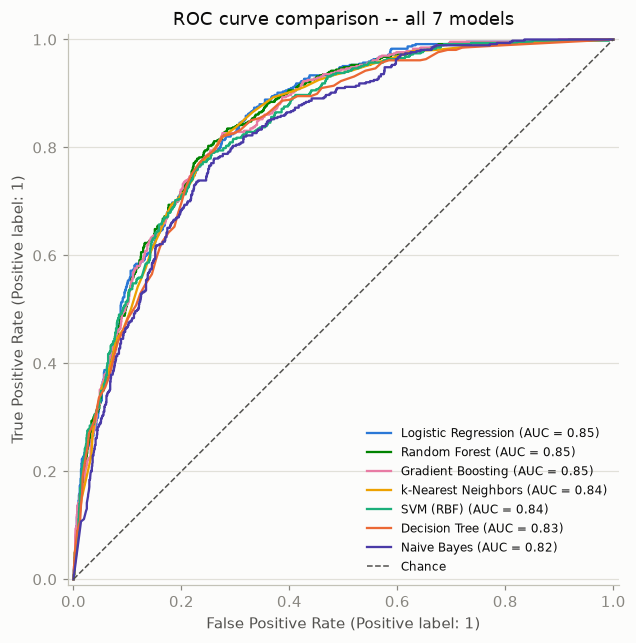

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
palette = CATEGORICAL + ["#000000"]
for i, name in enumerate(comparison["Model"]):
    RocCurveDisplay.from_estimator(fitted_pipes[name], X_test, y_test, ax=ax, name=name,
                                    curve_kwargs={"color": palette[i], "linewidth": 1.5})
ax.plot([0, 1], [0, 1], linestyle="--", color=INK_SECONDARY, linewidth=1, label="Chance")
ax.set_title("ROC curve comparison -- all 7 models")
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.show()

## The winner

In [15]:
winner_name = comparison.iloc[0]["Model"]
winner_pipe = fitted_pipes[winner_name]
winner_auc = comparison.iloc[0]["Test ROC-AUC"]

winner_pr_auc = comparison.iloc[0]["Test PR-AUC"]
winner_recall = comparison.iloc[0]["Recall (Churn)"]

print(f"Winner: {winner_name}")
print(f"Test ROC-AUC: {winner_auc:.4f}  (previous single-model RF baseline: 0.846)")
print(f"Test PR-AUC: {winner_pr_auc:.4f}")
print(f"Recall on churned class: {winner_recall:.4f}")

Winner: Logistic Regression
Test ROC-AUC: 0.8489  (previous single-model RF baseline: 0.846)
Test PR-AUC: 0.6554
Recall on churned class: 0.7923


## Chart: permutation importance for the winning model

Model-agnostic (unlike `.feature_importances_`, which only tree ensembles have) -- works whichever model won, by measuring how much test-set ROC-AUC drops when each feature is randomly shuffled.

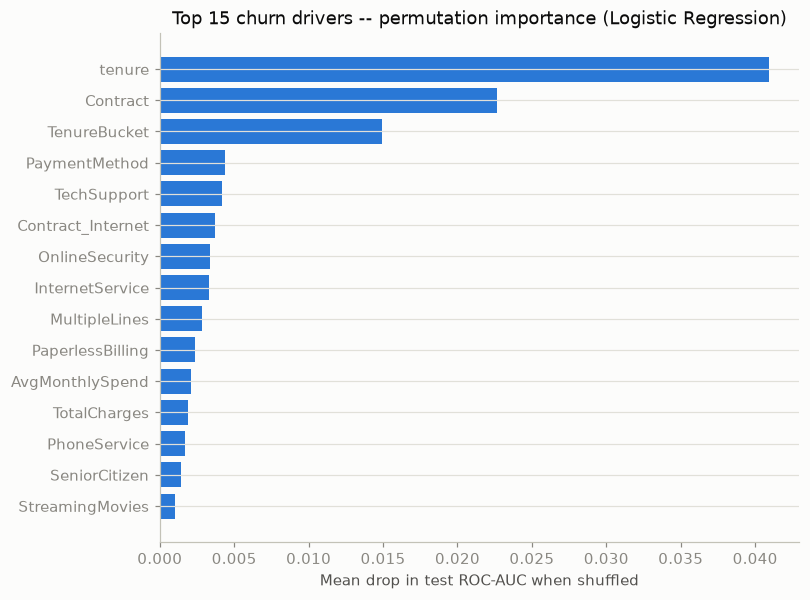

Top 10:
 tenure               0.040911
Contract             0.022681
TenureBucket         0.014914
PaymentMethod        0.004347
TechSupport          0.004189
Contract_Internet    0.003720
OnlineSecurity       0.003347
InternetService      0.003293
MultipleLines        0.002851
PaperlessBilling     0.002339
dtype: float64


In [16]:
perm = permutation_importance(
    winner_pipe, X_test, y_test, scoring="roc_auc", n_repeats=10,
    random_state=RANDOM_STATE, n_jobs=-1)

imp_series = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=True).tail(15)
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.barh(imp_series.index, imp_series.values, color=CATEGORICAL[0])
ax.set_title(f"Top 15 churn drivers -- permutation importance ({winner_name})")
ax.set_xlabel("Mean drop in test ROC-AUC when shuffled")
plt.show()
print("Top 10:\n", imp_series.sort_values(ascending=False).head(10))

## Save the winning pipeline

In [17]:
joblib.dump(winner_pipe, MODEL_PATH)
print(f"Saved {winner_name} pipeline to {MODEL_PATH}")

Saved Logistic Regression pipeline to C:\Users\DEVKUMAR\OneDrive\Desktop\DA_Project\models\best_churn_model.joblib
